# Oscillations and waves 2: Coupled oscillators

*Learning path: oscillations and waves, part 2 of 7.* [Index](README.md) · Previous: [The harmonic oscillator](01-harmonic-oscillator.ipynb) · Next: [The wave equation](03-wave-equation.ipynb)

Hang two identical pendulums from a slightly flexible rod and set one swinging. Little by little it slows down while
the other starts to swing, until the first stands still and the second has all the motion. Then it flows back. In 1665
Christiaan Huygens, ill in bed, noticed that two pendulum clocks on the same beam kept falling into step. Whenever
oscillators are linked, energy moves between them, and the motion that looks complicated is a sum of a few simple
patterns, the **normal modes**. Finding them is an eigenvalue problem, and it explains molecular vibrations, the
tones of a drum and, as the number of oscillators grows, waves.

**Who this is for.** You have done [lesson 1](01-harmonic-oscillator.ipynb) and know what eigenvalues and eigenvectors
are ([linear algebra 6](../linear-algebra/README.md)).

**What you will be able to do afterwards:**

1. write the equations of coupled oscillators as $\ddot x = -Kx$ with a matrix $K$;
2. find the normal modes as eigenvectors and the frequencies from the eigenvalues;
3. explain beats and the transfer of energy between weakly coupled oscillators;
4. find the modes of a chain of many masses, the bridge to waves.

Plan about an hour and a half.

## 1. Two masses, three springs

Two equal masses $m$ sit between two walls, joined to the walls and to each other by three equal springs $k$. Take
$k/m = 1$. If $x$ and $y$ are the displacements, the middle spring is stretched by $y - x$, so

$$\ddot x = -2x + y, \qquad \ddot y = x - 2y, \qquad\text{or}\qquad \begin{pmatrix}\ddot x\\ \ddot y\end{pmatrix} =
-K\begin{pmatrix}x\\ y\end{pmatrix}, \quad K = \begin{pmatrix}2 & -1\\ -1 & 2\end{pmatrix}.$$

Look for motions in which both masses swing at one frequency $\omega$ with fixed amplitudes $v$: $x(t) = v\cos\omega
t$. Then $Kv = \omega^2 v$, so $\omega^2$ is an **eigenvalue** of $K$ and $v$ its **eigenvector**:

In [1]:
K = [2, -1; -1, 2];
eig(K)
eigvec(K)

[1, 3]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

[1, -1;
 1,  1]

> `eigvec`: Eigenvectors, one per column, for exact eigenvalues.

Two normal modes. The eigenvalue 1 with $v = (1, 1)$: both masses move together, the middle spring never stretches,
and the frequency is that of one mass on one spring. The eigenvalue 3 with $v = (-1, 1)$: they move in opposite
directions, the middle spring works hard, and the frequency is $\sqrt3$ times higher.

Every motion is a sum of the two. Pull only the left mass to $x = 1$ and let go:

In [2]:
s = dsolve([d(x, t) == u, d(y, t) == v, d(u, t) == -2*x + y, d(v, t) == x - 2*y], [x, y, u, v], t, 0, [1, 0, 0, 0])

[(cos(t)+cos(sqrt(3)*t))/2, cos(t)/2-cos(sqrt(3)*t)/2, -(sqrt(3)*sin(sqrt(3)*t)+sin(t))/2, sqrt(3)*sin(sqrt(3)*t)/2-sin(t)/2]

> Linear system X' = A X + b with X = [x, y, u, v] and A = [ 0,  0, 1, 0;
>   0,  0, 0, 1;
>  -2,  1, 0, 0;
>   1, -2, 0, 0]. The solution is X(t) = e^(A t) X(0), with e^(A t) from expm(A, t). The answer lists x, y, u, v in that order.

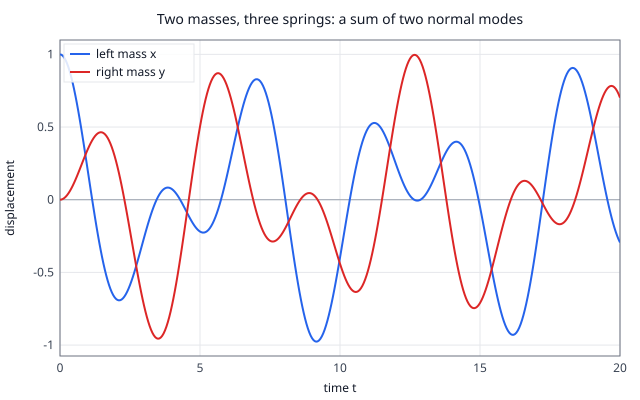

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
p = plot(s(1), t, 0, 20);
p = show(p, plot(s(2), t, 0, 20));
p = legend(p, "left mass x", "right mass y");
labels(title(p, "Two masses, three springs: a sum of two normal modes"), "time t", "displacement")

$x = \tfrac12(\cos t + \cos\sqrt3 t)$ and $y = \tfrac12(\cos t - \cos\sqrt3 t)$: half of each mode. Because
$\sqrt3$ is irrational, the motion never exactly repeats.

**Try this.** Start with $x = 1$ and $y = 1$. Which mode do you get, and why?

## 2. Weak coupling and beats

Now let the middle spring be weak, a tenth of the others: $\ddot x = -1.1x + 0.1y$ and $\ddot y = 0.1x - 1.1y$. The
two modes have frequencies $1$ and $\sqrt{1.2} \approx 1.095$, close together:

In [4]:
s = dsolve([d(x, t) == u, d(y, t) == v, d(u, t) == -11/10*x + y/10, d(v, t) == x/10 - 11/10*y], [x, y, u, v], t, 0, [1, 0, 0, 0])

[(cos(t)+cos(sqrt(6/5)*t))/2, cos(t)/2-cos(sqrt(6/5)*t)/2, -(sqrt(6/5)*sin(sqrt(6/5)*t)+sin(t))/2, sqrt(6/5)*sin(sqrt(6/5)*t)/2-sin(t)/2]

> Linear system X' = A X + b with X = [x, y, u, v] and A = [     0,      0, 1, 0;
>       0,      0, 0, 1;
>  -11/10,   1/10, 0, 0;
>    1/10, -11/10, 0, 0]. The solution is X(t) = e^(A t) X(0), with e^(A t) from expm(A, t). The answer lists x, y, u, v in that order.

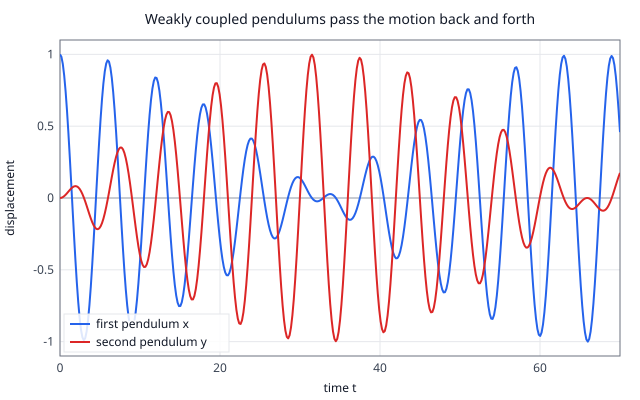

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
p = plot(s(1), t, 0, 70);
p = show(p, plot(s(2), t, 0, 70));
p = legend(p, "first pendulum x", "second pendulum y");
labels(title(p, "Weakly coupled pendulums pass the motion back and forth"), "time t", "displacement")

The two close frequencies drift in and out of step. Using $\cos a + \cos b = 2\cos\frac{a+b}2\cos\frac{a-b}2$, the
first pendulum moves as $\cos(\bar\omega t)\cos(\tfrac12\Delta\omega\,t)$: a fast swing inside a slow envelope. These
are **beats**. All the motion passes to the second pendulum in a time $\pi/\Delta\omega$:

In [6]:
eval(pi/(sqrt(6/5) - 1), 4)

32.92

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

about 33 time units, as in the plot. The weaker the coupling, the slower the exchange. Two guitar strings tuned
almost alike produce the same beats in sound (lesson 4), which is how guitarists tune by ear.

**Try this.** Halve the coupling (springs 1.05 and 0.05). How long does the transfer take now?

## 3. A molecule: carbon dioxide

A CO₂ molecule is a line O–C–O, with the two bonds as springs. In units where $k = 1$ and masses in daltons (16 for
oxygen, 12 for carbon), Newton's law reads $\ddot x = -Kx$ with $K = M^{-1}\times$(spring matrix):

In [7]:
K = [1/16, -1/16, 0; -1/12, 2/12, -1/12; 0, -1/16, 1/16];
eig(K)
eigvec(K)

[0, 1/16, 11/48]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

[1, -1,    1;
 1,  0, -8/3;
 1,  1,    1]

> `eigvec`: Eigenvectors, one per column, for exact eigenvalues.

Three modes, the columns of the eigenvector matrix. The eigenvalue 0 with $(1, 1, 1)$ is the whole molecule sliding
along, not a vibration. The eigenvalue $1/16$ with $(-1, 0, 1)$ is the **symmetric stretch**: the carbon stays still
while both oxygens move out and in together, at $\omega^2 = k/m_O$. The eigenvalue $11/48$ with $(1, -8/3, 1)$ is the
**asymmetric stretch**: the carbon moves against both oxygens, faster. The model's frequency ratio, against the
measured 1388 and 2349 per cm (Raman and infrared spectra):

In [8]:
eval([sqrt((11/48)/(1/16)), 2349/1388], 3)

[1.91, 1.69]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The model gets the order right and the ratio within 15%. The rest comes from what the model leaves out: the two bonds
are not independent springs, since stretching one changes the other. The asymmetric stretch is also the one that makes
CO₂ a greenhouse gas: it shifts the molecule's charge, so it absorbs infrared light, at 4.3 μm.

## 4. A chain of many masses

Now take $N$ masses in a row between two walls, all springs equal. $K$ has 2 on the diagonal and $-1$ beside it. For
$N = 8$:

In [9]:
N = 8;
M = zeros(N, N);
for k in 1:N
  M(k, k) = 2;
  if k < N
    M(k, k+1) = -1; M(k+1, k) = -1;
  end
end
[V, D] = eig(M);
eig(M)

[0.120614758428, 0.467911113762, 1.0, 1.65270364467, 2.34729635533, 3.0, 3.53208888624, 3.87938524157]

> eig: a symmetric matrix of numbers, diagonalized numerically (Jacobi rotations); eigenvalues in increasing order.

The frequencies are the square roots. Plot the first three modes, with the walls (displacement 0) added at both ends:

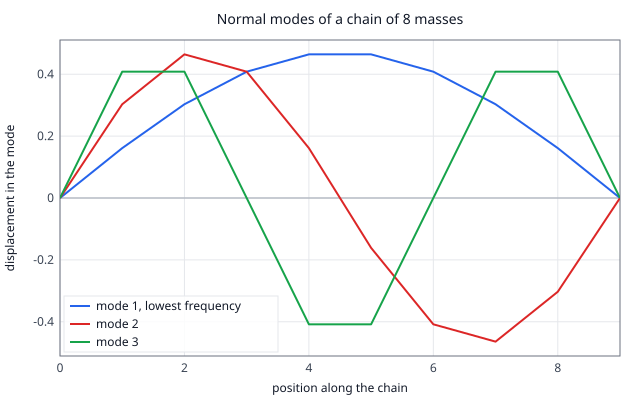

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
j = 0:N+1;
p = plot(j, [0; column(V, 1); 0]);
p = show(p, plot(j, [0; column(V, 2); 0]));
p = show(p, plot(j, [0; column(V, 3); 0]));
p = legend(p, "mode 1, lowest frequency", "mode 2", "mode 3");
labels(title(p, "Normal modes of a chain of 8 masses"), "position along the chain", "displacement in the mode")

Mode $n$ is a sampled sine wave with $n$ half-waves between the walls: $v_j = \sin(jn\pi/(N+1))$. Its eigenvalue is
$2 - 2\cos(n\pi/(N+1))$, so its frequency is

$$\omega_n = 2\sin\frac{n\pi}{2(N+1)}.$$

Check the first:

In [11]:
eval([sqrt(2 - 2*cos(pi/9)), 2*sin(pi/18)], 6)

[0.347296, 0.347296]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

For small $n$, $\omega_n \approx n\pi/(N+1)$: the frequencies are evenly spaced, like the harmonics of a string. Let
$N$ grow while the masses shrink and the chain becomes a continuous string; the modes become exact sine waves and the
equation becomes the **wave equation**, the subject of the next lesson. For large $n$ the frequencies bunch up below 2,
an effect called **dispersion** (lesson 5), and the reason a crystal can't carry sound above a certain frequency.

**Try this.** What is the highest mode of the chain? Plot `column(V, 8)`.

## Summary

* Coupled oscillators obey $\ddot x = -Kx$; normal modes are eigenvectors of $K$, with $\omega^2$ the eigenvalues.
* Every motion is a sum of normal modes, each swinging at its own frequency.
* Weak coupling splits the frequencies slightly; the result is beats, and energy passes back and forth in time
  $\pi/\Delta\omega$.
* A chain of $N$ masses has sine-wave modes with $\omega_n = 2\sin(n\pi/2(N+1))$; as $N$ grows, it becomes a string.

Next: [the wave equation](03-wave-equation.ipynb).

## Exercises

1. **Unequal masses.** Two masses $m$ and $2m$ between three equal springs. Find the normal modes. (Divide each
   equation by its mass first.)
2. **Coupled pendulums.** Two pendulums ($\omega_0^2 = g/\ell = 1$) are joined by a spring giving coupling $\kappa$.
   Show the modes are $\omega^2 = 1$ and $1 + 2\kappa$.
3. **Energy flow.** For the weakly coupled pair of section 2, plot the energy $\tfrac12(\dot x^2 + 1.1x^2)$ of the
   first pendulum.
4. **Triatomic, bent.** Water is bent, not straight, and has three vibrations instead of two. Which motion does the
   straight-line model of CO₂ leave out?
5. **Chain check.** Show that $v_j = \sin(jn\pi/(N+1))$ satisfies $-v_{j-1} + 2v_j - v_{j+1} = \lambda v_j$ with
   $\lambda = 2 - 2\cos(n\pi/(N+1))$. (Use $\sin(a + b) + \sin(a - b) = 2\sin a\cos b$.)
6. **Many masses.** Repeat section 4 with $N = 30$. How do the lowest frequencies compare with $n\pi/(N+1)$?

## Hints and answers

* **Section 1, Try this.** Only the in-phase mode: $x = y = \cos t$.
* **Section 2, Try this.** The modes are 1 and $\sqrt{1.1}$, so the transfer takes $\pi/(\sqrt{1.1} - 1) \approx 64$:
  about twice as long.
* **Section 4, Try this.** Neighbours move in opposite directions, with a sine envelope:
  $\omega_8 = 2\sin(8\pi/18) \approx 1.97$.
* **Exercise 1.** $K = [2, -1; -1/2, 1]$ gives $\omega^2 = (3 \pm \sqrt3)/2$.
* **Exercise 2.** $K = [1 + \kappa, -\kappa; -\kappa, 1 + \kappa]$ has eigenvalues $1$ and $1 + 2\kappa$.
* **Exercise 3.** It falls from 0.55 to nearly 0 at $t \approx 33$ and climbs back, a slow cosine squared.
* **Exercise 4.** Bending: the angle between the bonds changes. (CO₂ has a bending mode too, at 667 per cm, but it
  needs two dimensions.)
* **Exercise 5.** $\sin((j-1)a) + \sin((j+1)a) = 2\sin(ja)\cos a$.
* **Exercise 6.** $\omega_1 = 0.1013$ against $\pi/31 = 0.1013$; they agree to 0.1% for the lowest modes.

## Sources

1. C. Huygens, letter to the Royal Society, February 1665: the sympathy of clocks. See M. Bennett et al., "Huygens's
   clocks", *Proceedings of the Royal Society A* 458, 563–579 (2002).
2. A. P. French, *Vibrations and Waves*, Norton (1971), chapter 5.
3. G. Herzberg, *Molecular Spectra and Molecular Structure II: Infrared and Raman Spectra of Polyatomic Molecules*,
   Van Nostrand (1945): the CO₂ frequencies.